## ROBUSTEZ POR VENTANAS DE TIEMPO — LSTM (walk-forward)

Es la versión LSTM de `05c_svr_ventanas.ipynb`: mismo esquema de ventanas, mismo embargo, mismos portafolios y mismas métricas, para que SVR y LSTM se puedan comparar en igualdad de condiciones. Si necesitas recordar cómo funcionan las ventanas, la explicación completa está en ese notebook.

### Lo que es específico del LSTM
- **Secuencias:** cada muestra es una ventana de `SEQUENCE_LENGTH` días consecutivos de variables; el modelo predice el target del último día de la ventana. Para el primer día del test se usan como contexto los últimos días del train (solo variables, nunca sus targets).
- **Validación y parada:** `validation_split` reserva el tramo final del train y `EarlyStopping` vigila `val_loss`, como en `06_lstm`.
- **Semilla fija** por modelo, para que una misma configuración dé los mismos resultados al repetirla.
- **Caché por ventana:** cada ventana terminada se guarda en disco. Si el proceso se interrumpe (o cambias solo las secciones de análisis), al volver a correr retoma desde donde se quedó en vez de reentrenar todo.
- **Mismo `mu` sin mirar el futuro que en `05c`:** una sola predicción con las variables del último día antes del test.

### Aviso de tiempo
Son (activos × ventanas) redes neuronales: con 44 activos y 6 ventanas, 264 entrenamientos. Puede tardar de decenas de minutos a más de una hora según tu equipo. El caché evita perder avance.

Importación de librerías

In [1]:
import warnings
import pickle
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from pypfopt.expected_returns import mean_historical_return
from pypfopt.risk_models import CovarianceShrinkage
from pypfopt.efficient_frontier import EfficientFrontier

warnings.filterwarnings("ignore", category=UserWarning)


In [2]:
# ============================================================
# CONFIGURACIÓN
# ============================================================

UNIVERSE = "diversified"   # "diversified" (44 activos) o "original" (20 activos)

# Ventanas de test: (etiqueta, inicio del test, fin del test exclusivo; None = hasta el final de los datos)
TEST_WINDOWS = [
    ("2021",       "2021-01-01", "2022-01-01"),
    ("2022",       "2022-01-01", "2023-01-01"),
    ("2023",       "2023-01-01", "2024-01-01"),
    ("2024",       "2024-01-01", "2025-01-01"),
    ("2025",       "2025-01-01", "2026-01-01"),
    ("2026 (YTD)", "2026-01-01", None),
]

WINDOW_MODE = "expanding"   # "expanding" (train desde el inicio) o "rolling" (últimos N años)
ROLLING_TRAIN_YEARS = 3     # solo se usa si WINDOW_MODE == "rolling"
EMBARGO_DAYS = 5            # igual al horizonte del target
MIN_TRAIN_OBS = 250
MIN_TEST_OBS = 20

# Parámetros del LSTM (mismos que 06_lstm)
SEQUENCE_LENGTH = 20
EPOCHS = 50
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.15
PATIENCE = 5
SEED = 42
RESUME = True               # True = reutiliza las ventanas ya guardadas en el caché

FEATURE_COLS = [
    "return_1d", "return_5d", "return_10d", "return_21d", "return_63d",
    "sma_10", "sma_20", "sma_50",
    "ema_10", "ema_20", "ema_50",
    "vol_10", "vol_20", "vol_50",
    "rsi_14", "macd", "macd_signal",
    "bb_high", "bb_low"
]
TARGET_COL = "target_return_5d"

benchmark = "^GSPC"
RISK_FREE_RATE = 0.02
MAX_WEIGHT = 0.15
MIN_WEIGHT = 0.01   # misma cota mínima que los notebooks diversificados (pon 0 para quitarla)
PERIODS_PER_YEAR = 252 / 5

PROJECT_ROOT = Path.cwd().parent

data_folder = "processed_diversified" if UNIVERSE == "diversified" else "processed"
DATA_DIR = PROJECT_ROOT / "data" / data_folder

# El nombre de la carpeta incluye los parámetros clave, para que corridas distintas no se pisen
RUN_TAG = f"{UNIVERSE}_{WINDOW_MODE}_min{MIN_WEIGHT:g}_seq{SEQUENCE_LENGTH}"
RESULTS_DIR = PROJECT_ROOT / "results" / f"lstm_ventanas_{RUN_TAG}"
CACHE_DIR = RESULTS_DIR / "cache"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

FEATURES_FILE = DATA_DIR / "features_dataset.csv"
PRICES_FILE = DATA_DIR / "adjusted_prices.csv"
RETURNS_FILE = DATA_DIR / "daily_returns.csv"

print("Universo:", UNIVERSE, "| datos en:", DATA_DIR)
print("Corrida:", RUN_TAG)
print("Resultados en:", RESULTS_DIR)


Universo: diversified | datos en: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\data\processed_diversified
Corrida: diversified_expanding_min0.01_seq20
Resultados en: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\results\lstm_ventanas_diversified_expanding_min0.01_seq20


## Carga de datos

In [3]:
dataset = pd.read_csv(FEATURES_FILE, parse_dates=["Date"])
prices = pd.read_csv(PRICES_FILE, index_col=0, parse_dates=True)
returns = pd.read_csv(RETURNS_FILE, index_col=0, parse_dates=True)

tickers = [t for t in sorted(dataset["ticker"].unique()) if t != benchmark]

print("Activos:", len(tickers))
print("Features desde", dataset["Date"].min().date(), "hasta", dataset["Date"].max().date())


Activos: 44
Features desde 2018-04-05 hasta 2026-09-23


## Funciones auxiliares

In [4]:
def metrics_from_daily(r: pd.Series) -> dict:
    r = r.dropna()
    cum = (1 + r).cumprod()
    ann_return = r.mean() * 252
    ann_vol = r.std() * np.sqrt(252)
    return {
        "Retorno anualizado": ann_return,
        "Volatilidad anualizada": ann_vol,
        "Sharpe": (ann_return - RISK_FREE_RATE) / ann_vol,
        "Máx. drawdown": (cum / cum.cummax() - 1).min(),
        "Retorno total": cum.iloc[-1] - 1,
    }


def optimize_max_sharpe(mu: pd.Series, S: pd.DataFrame):
    """Máximo Sharpe con cota máxima y mínima. Si no hay solución (p. ej. ningún activo
    con mu > tasa libre de riesgo), usa mínima volatilidad y marca el caso."""

    def build():
        ef = EfficientFrontier(mu, S, weight_bounds=(0, MAX_WEIGHT))
        if MIN_WEIGHT > 0:
            ef.add_constraint(lambda w: w >= MIN_WEIGHT)
        return ef

    try:
        ef = build()
        ef.max_sharpe(risk_free_rate=RISK_FREE_RATE)
        return pd.Series(ef.clean_weights()), False
    except Exception:
        ef = build()
        ef.min_volatility()
        return pd.Series(ef.clean_weights()), True


def build_sequences(features: np.ndarray, targets: np.ndarray, seq_len: int):
    """La muestra j usa las filas j..j+seq_len-1 y su etiqueta es el target de la última fila."""
    X, y = [], []
    for j in range(len(features) - seq_len + 1):
        X.append(features[j:j + seq_len])
        y.append(targets[j + seq_len - 1])
    return np.array(X), np.array(y)


def make_model(n_features: int):
    model = Sequential([
        Input(shape=(SEQUENCE_LENGTH, n_features)),
        LSTM(32, return_sequences=True),
        Dropout(0.2),
        LSTM(16),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")
    return model


## Ciclo principal: una iteración por ventana

Para cada ventana y cada activo: se entrena un LSTM con el train (con embargo), se evalúa su R² en el test y se guarda una predicción a 5 días hecha con las últimas `SEQUENCE_LENGTH` filas previas al test, que es el `mu_lstm` que verá Markowitz. Luego se arman los portafolios y se miden sobre el año de test. Cada ventana terminada se guarda en el caché.

In [5]:
r2_records = []
metric_records = []
signal_records = []
fallback_records = []
curves = {}
weights_store = {}

for label, test_start, test_end in TEST_WINDOWS:

    safe_label = label.replace(" ", "_").replace("(", "").replace(")", "")
    cache_file = CACHE_DIR / f"ventana_{safe_label}.pkl"

    if RESUME and cache_file.exists():
        with open(cache_file, "rb") as f:
            cached = pickle.load(f)
        r2_records += cached["r2"]
        metric_records += cached["metrics"]
        signal_records.append(cached["signal"])
        fallback_records.append(cached["fallback"])
        curves[label] = cached["curve"]
        weights_store[label] = cached["weights"]
        print(f"Ventana {label}: cargada del caché")
        continue

    t_window = time.time()

    test_start = pd.Timestamp(test_start)
    test_end = pd.Timestamp(test_end) if test_end else dataset["Date"].max() + pd.Timedelta(days=1)

    if WINDOW_MODE == "rolling":
        train_start = test_start - pd.DateOffset(years=ROLLING_TRAIN_YEARS)
    else:
        train_start = dataset["Date"].min()

    print(f"\n=== Ventana {label}: train {train_start.date()} → {test_start.date()} | test → {test_end.date()} ===")

    train_win = dataset[(dataset["Date"] >= train_start) & (dataset["Date"] < test_start)]
    test_win = dataset[(dataset["Date"] >= test_start) & (dataset["Date"] < test_end)]

    win_r2 = []
    lstm_mu = {}

    for n_done, ticker in enumerate(tickers, start=1):

        train_t = train_win[train_win["ticker"] == ticker].sort_values("Date")
        test_t = test_win[test_win["ticker"] == ticker].sort_values("Date")

        if len(train_t) < MIN_TRAIN_OBS + EMBARGO_DAYS or len(test_t) < MIN_TEST_OBS:
            continue

        train_fit = train_t.iloc[:-EMBARGO_DAYS]   # embargo: se quitan las filas cuyo target toca el test

        scaler_X = StandardScaler().fit(train_fit[FEATURE_COLS])
        scaler_y = StandardScaler().fit(train_fit[[TARGET_COL]])

        X_train, y_train = build_sequences(
            scaler_X.transform(train_fit[FEATURE_COLS]),
            scaler_y.transform(train_fit[[TARGET_COL]]).ravel(),
            SEQUENCE_LENGTH
        )

        # Test: se antepone contexto del train (solo variables) para poder armar la primera secuencia
        test_ctx = pd.concat([train_t.iloc[-(SEQUENCE_LENGTH - 1):], test_t])
        X_test, _ = build_sequences(
            scaler_X.transform(test_ctx[FEATURE_COLS]),
            np.zeros(len(test_ctx)),
            SEQUENCE_LENGTH
        )
        y_true = test_t[TARGET_COL].values

        # Secuencia con la que se decide el portafolio: las últimas filas antes del test
        X_decision = scaler_X.transform(train_t[FEATURE_COLS].iloc[-SEQUENCE_LENGTH:])[None, ...]

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = make_model(len(FEATURE_COLS))

        history = model.fit(
            X_train, y_train,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            validation_split=VALIDATION_SPLIT,
            callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
            verbose=0
        )

        # --- Evaluación en el test ---
        y_pred = scaler_y.inverse_transform(model.predict(X_test, verbose=0)).ravel()

        win_r2.append({
            "ventana": label,
            "ticker": ticker,
            "R2": r2_score(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "epocas": len(history.history["loss"]),
        })

        # --- Una sola predicción para decidir el portafolio (sin mirar el test) ---
        pred_5d = scaler_y.inverse_transform(model.predict(X_decision, verbose=0)).ravel()[0]
        lstm_mu[ticker] = (1 + pred_5d) ** PERIODS_PER_YEAR - 1

        if n_done % 10 == 0:
            print(f"  {n_done}/{len(tickers)} activos | {time.time() - t_window:.0f}s")

    # --- Portafolios: toda la estimación usa solo datos anteriores al test ---
    train_prices = prices[(prices.index >= train_start) & (prices.index < test_start)]
    universe = [t for t in tickers if t in lstm_mu and t in train_prices.columns and train_prices[t].notna().all()]

    mu_hist = mean_historical_return(train_prices[universe])
    S = CovarianceShrinkage(train_prices[universe]).ledoit_wolf()
    mu_lstm_s = pd.Series(lstm_mu).reindex(universe)

    w_eq = pd.Series(1 / len(universe), index=universe)
    w_hist, fb_hist = optimize_max_sharpe(mu_hist, S)
    w_lstm, fb_lstm = optimize_max_sharpe(mu_lstm_s, S)

    fallback = {"ventana": label, "Markowitz hist usó fallback": fb_hist, "Markowitz+LSTM usó fallback": fb_lstm}
    weights = pd.DataFrame({"Markowitz (mu histórico)": w_hist, "Markowitz + LSTM": w_lstm, "Equal Weight": w_eq})

    # --- Retornos del año de test ---
    rets = returns[(returns.index >= test_start) & (returns.index < test_end)]
    asset_rets = rets[universe].fillna(0)

    daily = pd.DataFrame({
        "Equal Weight": (asset_rets * w_eq).sum(axis=1),
        "Markowitz (mu histórico)": (asset_rets * w_hist.reindex(universe).fillna(0)).sum(axis=1),
        "Markowitz + LSTM": (asset_rets * w_lstm.reindex(universe).fillna(0)).sum(axis=1),
        "S&P 500": rets[benchmark],
    }).dropna()

    curve = (1 + daily).cumprod()

    win_metrics = [
        {"ventana": label, "estrategia": strategy, **metrics_from_daily(daily[strategy])}
        for strategy in daily.columns
    ]

    # --- ¿El ranking de mu se parece al retorno realmente obtenido? (Spearman) ---
    realized = (1 + asset_rets).prod() - 1
    signal = {
        "ventana": label,
        "Spearman mu histórico vs. realizado": mu_hist.corr(realized, method="spearman"),
        "Spearman mu LSTM vs. realizado": mu_lstm_s.corr(realized, method="spearman"),
    }

    r2_records += win_r2
    metric_records += win_metrics
    signal_records.append(signal)
    fallback_records.append(fallback)
    curves[label] = curve
    weights_store[label] = weights

    with open(cache_file, "wb") as f:
        pickle.dump({"r2": win_r2, "metrics": win_metrics, "signal": signal,
                     "fallback": fallback, "curve": curve, "weights": weights}, f)

    print(f"Ventana {label} lista en {(time.time() - t_window) / 60:.1f} min (guardada en el caché)")

r2_df = pd.DataFrame(r2_records)
metrics_df = pd.DataFrame(metric_records)
signal_df = pd.DataFrame(signal_records).set_index("ventana")
fallback_df = pd.DataFrame(fallback_records).set_index("ventana")

print("\nListo.")



=== Ventana 2021: train 2018-04-05 → 2021-01-01 | test → 2022-01-01 ===

  10/44 activos | 108s
  20/44 activos | 316s
  30/44 activos | 515s
  40/44 activos | 646s
Ventana 2021 lista en 11.4 min (guardada en el caché)

=== Ventana 2022: train 2018-04-05 → 2022-01-01 | test → 2023-01-01 ===
  10/44 activos | 150s
  20/44 activos | 408s
  30/44 activos | 634s
  40/44 activos | 860s
Ventana 2022 lista en 15.5 min (guardada en el caché)

=== Ventana 2023: train 2018-04-05 → 2023-01-01 | test → 2024-01-01 ===
  10/44 activos | 117s
  20/44 activos | 228s
  30/44 activos | 364s
  40/44 activos | 531s
Ventana 2023 lista en 10.0 min (guardada en el caché)

=== Ventana 2024: train 2018-04-05 → 2024-01-01 | test → 2025-01-01 ===
  10/44 activos | 152s
  20/44 activos | 315s
  30/44 activos | 476s
  40/44 activos | 662s
Ventana 2024 lista en 12.4 min (guardada en el caché)

=== Ventana 2025: train 2018-04-05 → 2025-01-01 | test → 2026-01-01 ===
  10/44 activos | 229s
  20/44 activos | 421s
  30

## 1. Capacidad predictiva por ventana (R² del LSTM)

Si el modelo capturara señal real, el R² promedio debería ser positivo de forma consistente en varias ventanas. También se muestra cuántas épocas entrenó en promedio: si `EarlyStopping` lo detiene en muy pocas épocas, la pérdida de validación empeora casi de inmediato, señal de que no hay mucho que aprender.

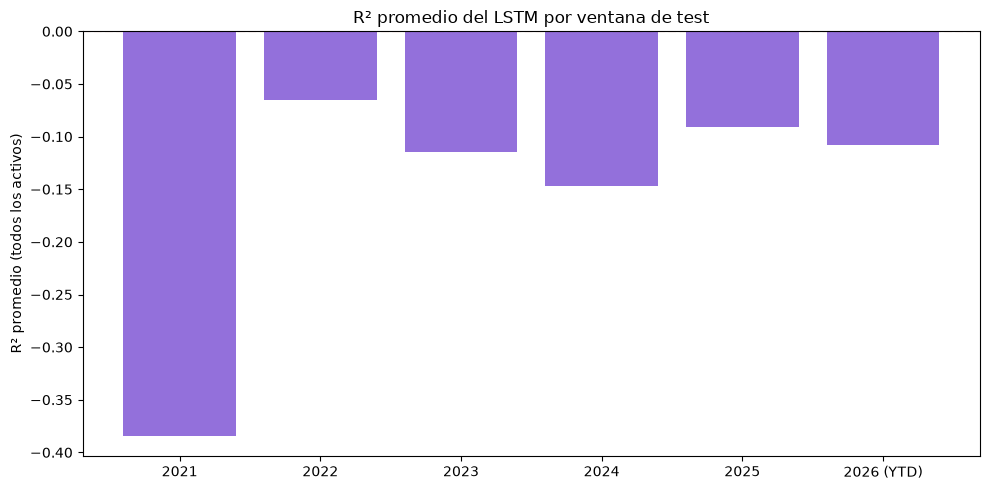

,R2_promedio,R2_mediana,pct_activos_R2_positivo,epocas_promedio
ventana,,,,
2021,-0.3842,-0.1551,0.0455,7.5000
2022,-0.0652,-0.0407,0.2955,7.0455
2023,-0.1148,-0.0824,0.2500,7.3409
2024,-0.1465,-0.1301,0.0682,6.5682
2025,-0.0910,-0.0371,0.1364,7.3182
2026 (YTD),-0.1076,-0.0617,0.1364,7.7045


In [6]:
window_order = [w[0] for w in TEST_WINDOWS]

r2_summary = r2_df.groupby("ventana").agg(
    R2_promedio=("R2", "mean"),
    R2_mediana=("R2", "median"),
    pct_activos_R2_positivo=("R2", lambda s: (s > 0).mean()),
    epocas_promedio=("epocas", "mean"),
).reindex(window_order)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(r2_summary.index, r2_summary["R2_promedio"], color="mediumpurple")
ax.axhline(0, color="red", linestyle="--", alpha=0.6)
ax.set_title("R² promedio del LSTM por ventana de test")
ax.set_ylabel("R² promedio (todos los activos)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_r2_por_ventana.png", dpi=300, bbox_inches="tight")
plt.show()

r2_summary.round(4)


## 2. Métricas de los portafolios por ventana

In [7]:
def pivot_metric(metric):
    return metrics_df.pivot(index="ventana", columns="estrategia", values=metric).reindex(window_order)

sharpe_table = pivot_metric("Sharpe")
return_table = pivot_metric("Retorno anualizado")
drawdown_table = pivot_metric("Máx. drawdown")

print("SHARPE RATIO por ventana")
display(sharpe_table.round(3))
print("RETORNO ANUALIZADO por ventana")
display(return_table.round(3))
print("MÁXIMO DRAWDOWN por ventana")
display(drawdown_table.round(3))


SHARPE RATIO por ventana


estrategia,Equal Weight,Markowitz (mu histórico),Markowitz + LSTM,S&P 500
ventana,,,,
2021,2.263,2.170,2.023,1.732
2022,-0.414,-0.651,-0.741,-0.860
2023,1.870,2.081,2.514,1.584
2024,2.088,2.206,2.103,1.562
2025,0.951,1.276,1.053,0.802
2026 (YTD),1.457,1.009,1.158,1.150


RETORNO ANUALIZADO por ventana


estrategia,Equal Weight,Markowitz (mu histórico),Markowitz + LSTM,S&P 500
ventana,,,,
2021,0.297,0.350,0.306,0.247
2022,-0.072,-0.143,-0.170,-0.188
2023,0.252,0.308,0.435,0.227
2024,0.230,0.439,0.311,0.218
2025,0.168,0.295,0.218,0.170
2026 (YTD),0.160,0.158,0.167,0.173


MÁXIMO DRAWDOWN por ventana


estrategia,Equal Weight,Markowitz (mu histórico),Markowitz + LSTM,S&P 500
ventana,,,,
2021,-0.047,-0.096,-0.092,-0.052
2022,-0.202,-0.205,-0.252,-0.254
2023,-0.089,-0.096,-0.097,-0.103
2024,-0.048,-0.118,-0.073,-0.085
2025,-0.153,-0.210,-0.183,-0.189
2026 (YTD),-0.063,-0.084,-0.070,-0.091


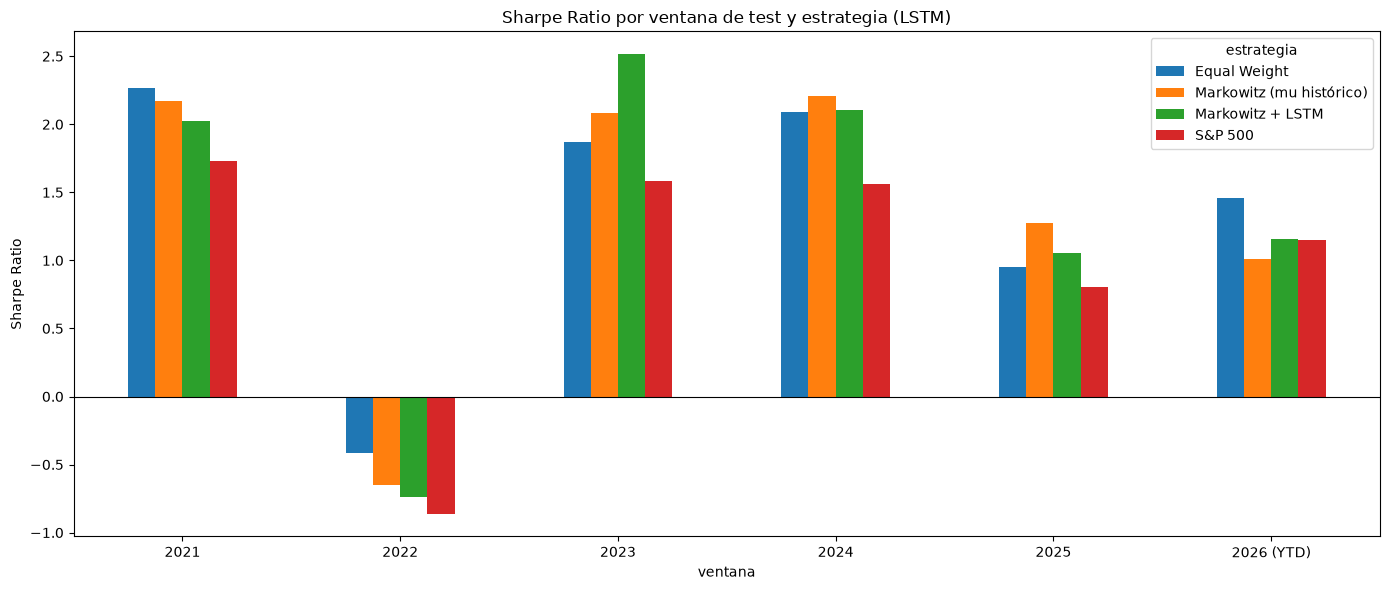

In [8]:
sharpe_table.plot(kind="bar", figsize=(14, 6), title="Sharpe Ratio por ventana de test y estrategia (LSTM)")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Sharpe Ratio")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_sharpe_por_ventana.png", dpi=300, bbox_inches="tight")
plt.show()


## 3. Crecimiento de $1 en cada ventana de test

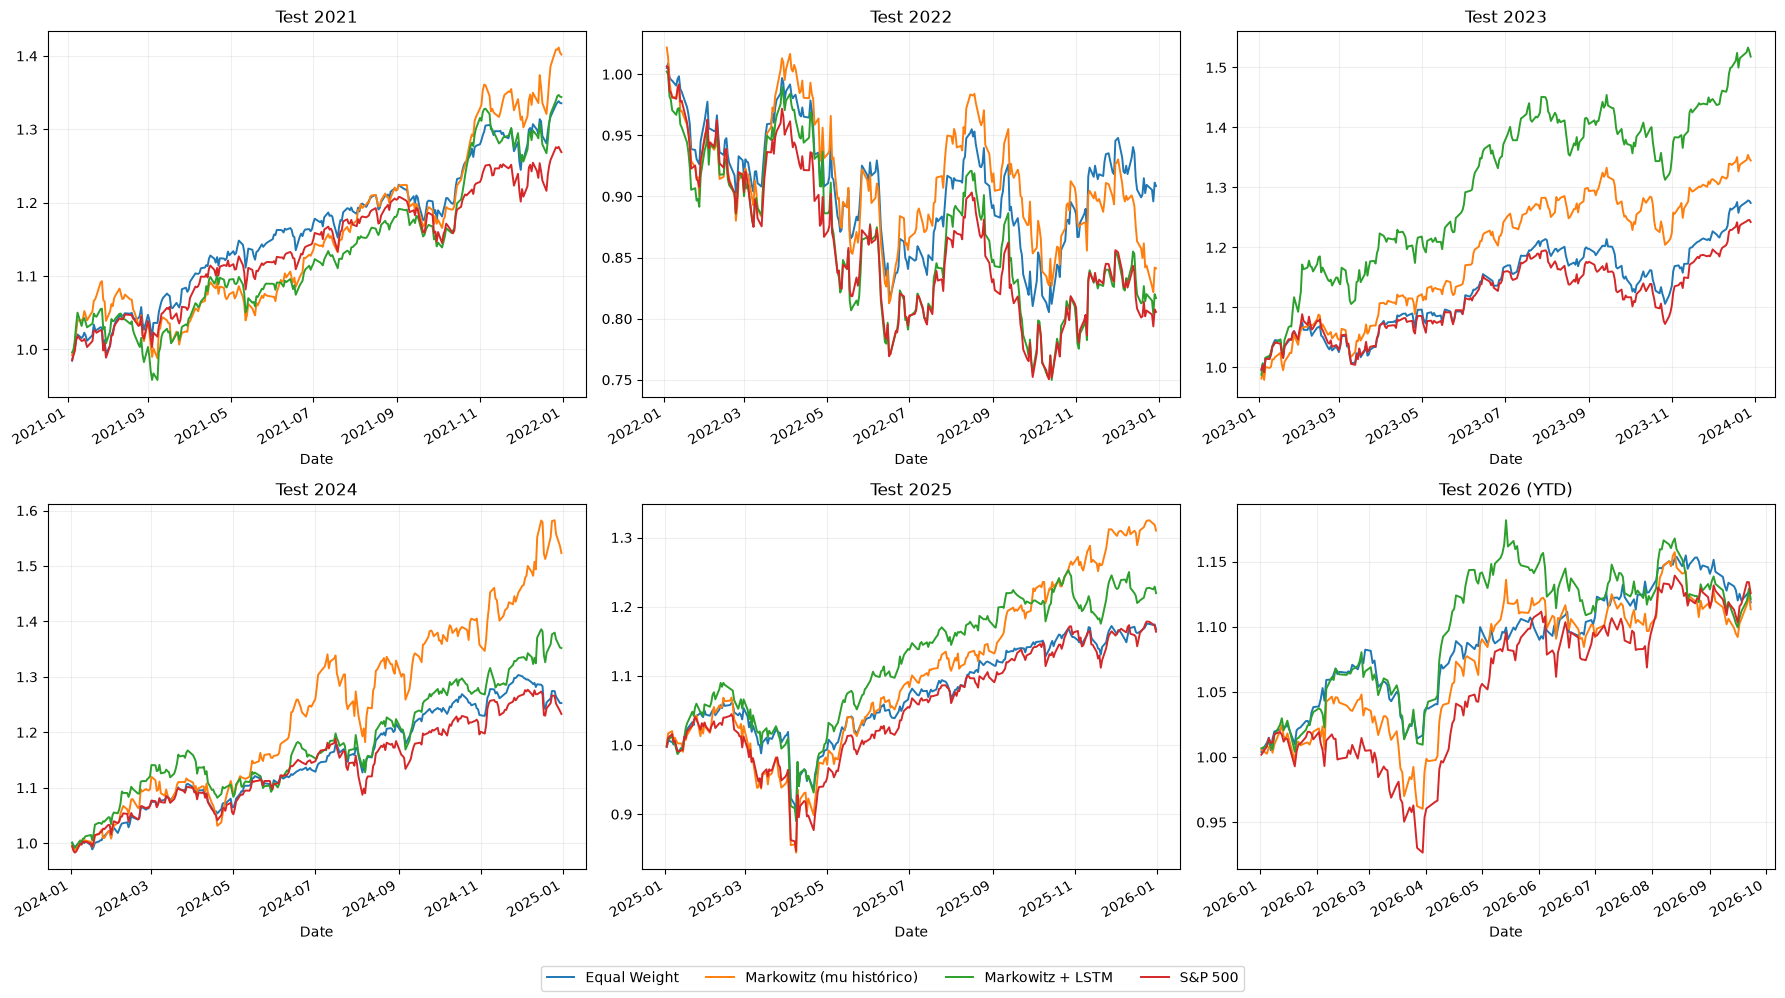

In [9]:
n = len(curves)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows), squeeze=False)

for ax, (label, curve) in zip(axes.flatten(), curves.items()):
    curve.plot(ax=ax, linewidth=1.4, legend=False)
    ax.set_title(f"Test {label}")
    ax.grid(alpha=0.2)

for ax in axes.flatten()[n:]:
    ax.axis("off")

handles, labels = axes.flatten()[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(RESULTS_DIR / "03_curvas_por_ventana.png", dpi=300, bbox_inches="tight")
plt.show()


## 4. Consistencia entre ventanas

En cuántas ventanas cada estrategia supera a Equal Weight y al S&P 500, y qué tan estable es su Sharpe.

In [10]:
def consistency_table(sharpe_df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        strategy: {
            "Sharpe promedio": sharpe_df[strategy].mean(),
            "Desv. est. del Sharpe": sharpe_df[strategy].std(),
            "Peor ventana (Sharpe)": sharpe_df[strategy].min(),
            "Ventanas que supera a Equal Weight": int((sharpe_df[strategy] > sharpe_df["Equal Weight"]).sum()),
            "Ventanas que supera al S&P 500": int((sharpe_df[strategy] > sharpe_df["S&P 500"]).sum()),
        }
        for strategy in sharpe_df.columns
    }).T


consistency = consistency_table(sharpe_table)

print(f"Total de ventanas: {len(sharpe_table)}")
consistency.round(3)


Total de ventanas: 6


,Sharpe promedio,Desv. est. del Sharpe,Peor ventana (Sharpe),Ventanas que supera a Equal Weight,Ventanas que supera al S&P 500
Equal Weight,1.369,0.993,-0.414,0.0,6.0
Markowitz (mu histórico),1.349,1.101,-0.651,3.0,5.0
Markowitz + LSTM,1.352,1.173,-0.741,3.0,6.0
S&P 500,0.995,0.971,-0.860,0.0,0.0


## 5. ¿El ranking de retornos esperados se parece a lo que realmente pasó?

Correlación de Spearman entre el `mu` con el que se decidió y el retorno realmente obtenido por cada activo durante el test. Cerca de 0 = no hay poder de ordenar ganadores y perdedores.

,Spearman mu histórico vs. realizado,Spearman mu LSTM vs. realizado
ventana,,
2021,-0.014,0.134
2022,-0.523,-0.117
2023,0.039,0.409
2024,0.185,0.122
2025,0.238,0.094
2026 (YTD),-0.114,-0.037


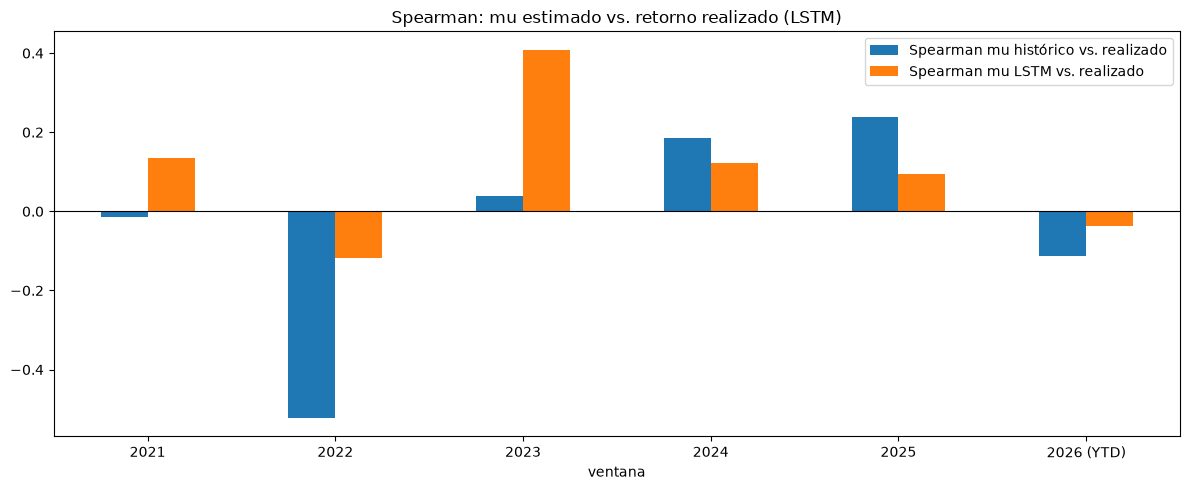

Ventanas donde Max Sharpe tuvo que usar el respaldo de mínima volatilidad:


,Markowitz hist usó fallback,Markowitz+LSTM usó fallback
ventana,,
2021,False,False
2022,False,False
2023,False,False
2024,False,False
2025,False,False
2026 (YTD),False,False


In [11]:
display(signal_df.round(3))

signal_df.plot(kind="bar", figsize=(12, 5), title="Spearman: mu estimado vs. retorno realizado (LSTM)")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04_spearman_por_ventana.png", dpi=300, bbox_inches="tight")
plt.show()

print("Ventanas donde Max Sharpe tuvo que usar el respaldo de mínima volatilidad:")
display(fallback_df)


## 6. Comparación SVR vs. LSTM (opcional)

Si ya corriste `05c_svr_ventanas.ipynb` **con la misma configuración** (mismo universo, `WINDOW_MODE` y `MIN_WEIGHT`), aquí se agrega su columna a la tabla de Sharpe. Equal Weight, Markowitz con `mu` histórico y el S&P 500 son idénticos en ambas corridas, por eso solo se toma de SVR la columna de Markowitz + SVR. Si cambiaste alguno de esos parámetros en una sola de las dos corridas, la comparación no es válida.

SHARPE RATIO por ventana (todas las estrategias)


estrategia,Equal Weight,Markowitz (mu histórico),Markowitz + SVR,Markowitz + LSTM,S&P 500
ventana,,,,,
2021,2.263,2.170,1.614,2.023,1.732
2022,-0.414,-0.651,-0.534,-0.741,-0.860
2023,1.870,2.081,2.020,2.514,1.584
2024,2.088,2.206,1.942,2.103,1.562
2025,0.951,1.276,0.630,1.053,0.802
2026 (YTD),1.457,1.009,1.589,1.158,1.150


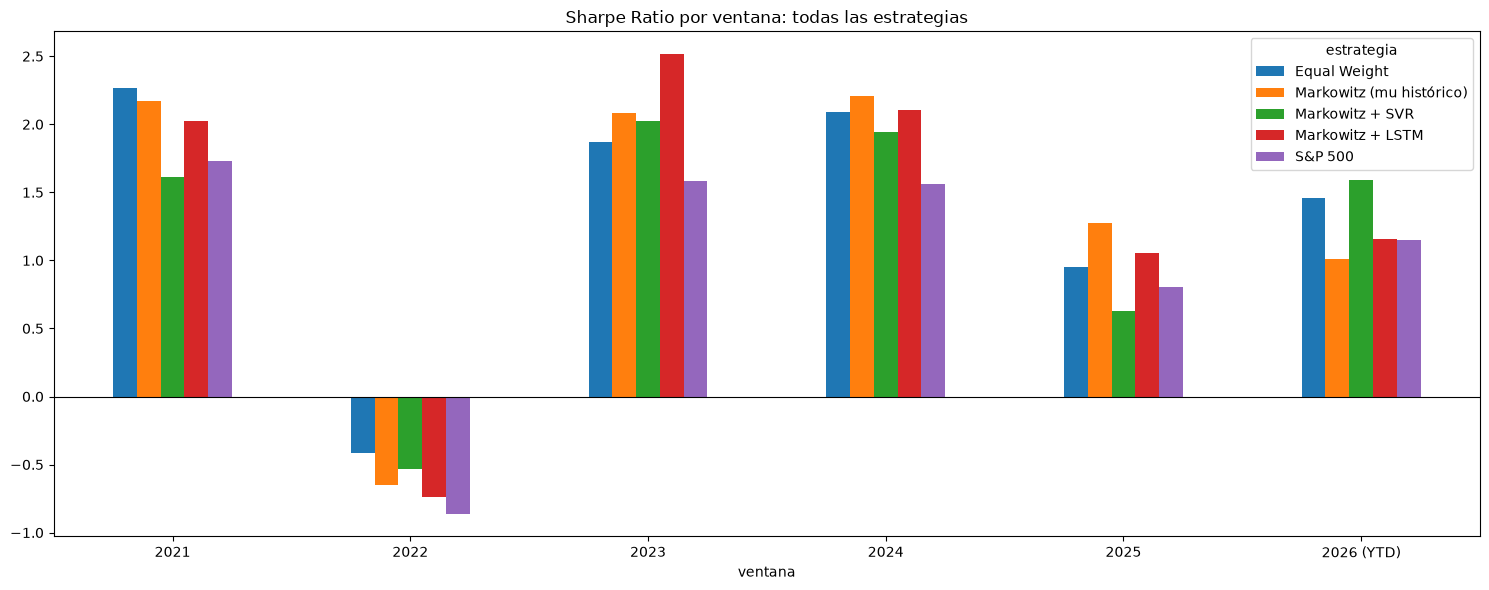

CONSISTENCIA ENTRE VENTANAS (todas las estrategias)


,Sharpe promedio,Desv. est. del Sharpe,Peor ventana (Sharpe),Ventanas que supera a Equal Weight,Ventanas que supera al S&P 500
Equal Weight,1.369,0.993,-0.414,0.0,6.0
Markowitz (mu histórico),1.349,1.101,-0.651,3.0,5.0
Markowitz + SVR,1.210,0.988,-0.534,2.0,4.0
Markowitz + LSTM,1.352,1.173,-0.741,3.0,6.0
S&P 500,0.995,0.971,-0.860,0.0,0.0


LSTM supera a SVR en 4 de 6 ventanas


In [12]:
SVR_RESULTS_DIR = PROJECT_ROOT / "results" / f"svr_ventanas_{UNIVERSE}"   # ajusta la ruta si la renombraste
svr_file = SVR_RESULTS_DIR / "sharpe_por_ventana.csv"

if svr_file.exists():
    svr_sharpe = pd.read_csv(svr_file, index_col=0)
    svr_sharpe.index = svr_sharpe.index.astype(str)

    combined = sharpe_table.copy()
    combined["Markowitz + SVR"] = svr_sharpe["Markowitz + SVR"].reindex(window_order)
    combined = combined[["Equal Weight", "Markowitz (mu histórico)", "Markowitz + SVR", "Markowitz + LSTM", "S&P 500"]]

    print("SHARPE RATIO por ventana (todas las estrategias)")
    display(combined.round(3))

    combined.plot(kind="bar", figsize=(15, 6), title="Sharpe Ratio por ventana: todas las estrategias")
    plt.axhline(0, color="black", linewidth=0.8)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "05_sharpe_todas_las_estrategias.png", dpi=300, bbox_inches="tight")
    plt.show()

    print("CONSISTENCIA ENTRE VENTANAS (todas las estrategias)")
    consistency_all = consistency_table(combined)
    display(consistency_all.round(3))

    wins_lstm_vs_svr = int((combined["Markowitz + LSTM"] > combined["Markowitz + SVR"]).sum())
    print(f"LSTM supera a SVR en {wins_lstm_vs_svr} de {len(combined)} ventanas")
else:
    print("No se encontró", svr_file, "- corre antes 05c_svr_ventanas.ipynb o ajusta SVR_RESULTS_DIR.")


## Cómo leer los resultados

- **R² por ventana y épocas:** R² negativo o cercano a 0 en todas las ventanas, con pocas épocas de entrenamiento, indica que la falta de señal no es casualidad de un corte.
- **Sharpe y consistencia:** si una estrategia gana en una ventana pero pierde en otra, su desempeño depende del régimen de mercado, no del método.
- **Spearman:** un valor que cambia de signo entre ventanas indica ruido.
- Con 6 ventanas (una parcial) las conclusiones son orientativas, no estadísticamente concluyentes.

## Guardar resultados

In [13]:
r2_df.to_csv(RESULTS_DIR / "r2_por_activo_y_ventana.csv", index=False)
metrics_df.to_csv(RESULTS_DIR / "metricas_por_ventana.csv", index=False)
sharpe_table.to_csv(RESULTS_DIR / "sharpe_por_ventana.csv")
consistency.to_csv(RESULTS_DIR / "consistencia_entre_ventanas.csv")
signal_df.to_csv(RESULTS_DIR / "spearman_por_ventana.csv")

for label, w in weights_store.items():
    w.to_csv(RESULTS_DIR / f"pesos_ventana_{label.replace(' ', '_').replace('(', '').replace(')', '')}.csv")

print("Resultados guardados en:", RESULTS_DIR)


Resultados guardados en: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\results\lstm_ventanas_diversified_expanding_min0.01_seq20
